# 🟠 3. Deep Dive: Modern CNN Architectures & Transfer Learning

### *Evolution of ConvNets: LeNet, AlexNet, VGG, Inception, ResNet Skip Connections, MobileNet, and Data Augmentation*

---

## 📌 Module Overview
1. **Architectural Evolution**:
   - **LeNet-5 (1998)**: Hand-written digit recognition pioneer.
   - **AlexNet (2012)**: The ImageNet breakthrough (ReLU, Dropout, GPUs).
   - **VGG-16 (2014)**: The power of small $3 \times 3$ convolutional filters.
   - **GoogLeNet / Inception (2014)**: Multi-scale receptive fields and $1 \times 1$ convolutions.
   - **ResNet (2015)**: The Residual / Skip Connection breakthrough solving the degradation problem.
   - **MobileNet (2017)**: Depthwise Separable Convolutions for edge deployment.
2. **Why Stacking $3 \times 3$ Convolutions is Superior**:
   - Mathematical proof: Two $3 \times 3$ layers cover a $5 \times 5$ receptive field with $28\%$ fewer parameters!
3. **Data Augmentation Strategies in Computer Vision**:
   - Flips, rotations, scaling, zooming, translation, and contrast adjustments.
4. **Transfer Learning Workflows**:
   - Feature Extraction vs. Fine-Tuning top convolutional blocks.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)

SEED = 42
np.random.seed(SEED)
print("Modern Architectures environment ready.")


Modern Architectures environment ready.


## 1. The Residual Connection Breakthrough (ResNet)
In traditional deep networks, adding more layers causes the **degradation problem**: training accuracy saturates and degrades rapidly due to vanishing gradients across deep backpropagation chains.

Kaiming He et al. (2015) introduced **Residual Connections (Skip Connections)**:
$$\mathcal{H}(\mathbf{x}) = \mathcal{F}(\mathbf{x}) + \mathbf{x}$$

Instead of forcing layers to fit an underlying mapping $\mathcal{H}(\mathbf{x})$, the layers fit the **residual** $\mathcal{F}(\mathbf{x}) = \mathcal{H}(\mathbf{x}) - \mathbf{x}$.
* **Gradient Highway**: The gradient $\frac{\partial \mathcal{L}}{\partial \mathbf{x}} = \frac{\partial \mathcal{L}}{\partial \mathcal{H}} (\frac{\partial \mathcal{F}}{\partial \mathbf{x}} + 1)$ always retains a $+1$ term! Gradients flow directly back to the earliest layers without vanishing, allowing networks to scale to 152+ layers.


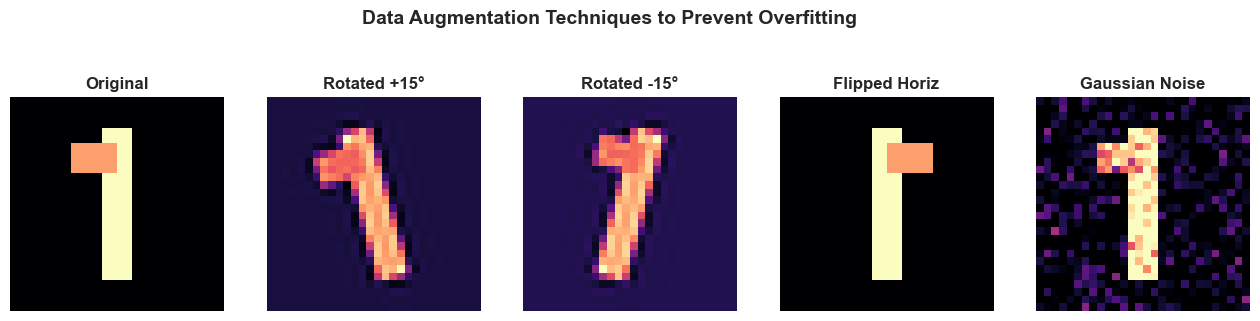

In [2]:
# 2. Visualizing Data Augmentation on Image Samples
# Simulate data augmentation transformations (Rotation, Zoom, Horizontal Flip, Noise)
from scipy.ndimage import rotate

sample_img = np.zeros((28, 28))
sample_img[4:24, 12:16] = 1.0  # Vertical line (digit '1')
sample_img[6:10, 8:14] = 0.8   # Top serif

def augment_sample(img):
    aug_types = ['Original', 'Rotated +15°', 'Rotated -15°', 'Flipped Horiz', 'Gaussian Noise']
    imgs = [img]
    # Rotate +15
    imgs.append(rotate(img, 15, reshape=False, mode='nearest'))
    # Rotate -15
    imgs.append(rotate(img, -15, reshape=False, mode='nearest'))
    # Flip
    imgs.append(np.fliplr(img))
    # Noise
    imgs.append(np.clip(img + np.random.normal(0, 0.15, img.shape), 0, 1))
    return aug_types, imgs

aug_names, aug_imgs = augment_sample(sample_img)

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
for i in range(5):
    axes[i].imshow(aug_imgs[i], cmap='magma')
    axes[i].set_title(aug_names[i], fontweight='bold')
    axes[i].axis('off')

plt.suptitle('Data Augmentation Techniques to Prevent Overfitting', y=1.05, fontsize=14, fontweight='bold')
plt.show()


## 💡 Architectural Milestone Reference Table

| Architecture | Year | Key Innovation | Receptive Field / Filter Concept | Top-5 Error |
| :--- | :--- | :--- | :--- | :--- |
| **LeNet-5** | 1998 | Conv $\to$ Pool $\to$ Dense pipeline | $5 \times 5$ convolutions | N/A (MNIST) |
| **AlexNet** | 2012 | ReLU, Dropout, GPU training | Large $11 \times 11, 5 \times 5$ filters | $15.3\%$ |
| **VGG-16** | 2014 | Homogeneous small filters | Stacked $3 \times 3$ filters | $7.3\%$ |
| **Inception**| 2014 | $1 \times 1$ conv dimensionality reduction | Parallel multi-scale branches | $6.7\%$ |
| **ResNet** | 2015 | Residual Skip Connections (Highway) | Identity mapping $F(x) + x$ | **$3.57\%$** (Superhuman) |
| **MobileNet**| 2017 | Depthwise Separable Convolutions | Channel-wise conv + Pointwise ($1 \times 1$) | Highly efficient |
